# 00 — Start here: your practical OpenCV learning path

**Level:** Orientation  
**Prerequisites:** No OpenCV experience; basic computer use

## What you will build and learn

- Learn how notebook cells and kernels work.
- Verify the project environment and run your first image pipeline.
- Choose a study rhythm and learn how to experiment deliberately.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Understand your tools

**Python** is the language. **NumPy** stores images as grids of numbers.
**OpenCV** provides image/video algorithms. **Matplotlib** displays results inside
the page. **JupyterLab** lets you mix explanations with executable Python cells.

A **kernel** is the running Python process. Variables persist between cells until
you restart it. A number such as `[4]` records execution order, not the position of
a cell. Run from top to bottom so the code and your mental model agree.

Click a code cell and press **Shift+Enter**. A `[*]` means it is still running.
Use **Kernel → Interrupt Kernel** for an unexpectedly long calculation. Use
**Kernel → Restart Kernel and Run All Cells** to reproduce the complete lesson.


In [2]:
import sys
import platform
import importlib.metadata as metadata

print("Python executable:", sys.executable)
print("Python version:", platform.python_version())
for package in ["opencv-python-headless", "numpy", "matplotlib", "jupyterlab"]:
    print(f"{package}: {metadata.version(package)}")
assert sys.version_info >= (3, 10), "Use a supported modern Python environment."


Python executable: C:\Users\Hareram ray\AI\OpencvPractical\.venv\Scripts\python.exe
Python version: 3.13.15
opencv-python-headless: 4.14.0.94
numpy: 2.5.3
matplotlib: 3.11.2
jupyterlab: 4.6.4


**Expected:** the interpreter path contains this project's `.venv`, and four package
versions are printed. If imports fail, choose **Python (OpenCV Practical)** as your
kernel. The README contains installation commands and troubleshooting.

## Step 2 — Your first image

`make_scene()` draws an original sample with rectangles, a circle, text, and stripes.
It returns a NumPy array. For a color image the shape is `(height, width, channels)`.
Each `uint8` channel stores an integer from 0 to 255.


Shape: (420, 640, 3) Data type: uint8
A BGR pixel: [210  90  25]


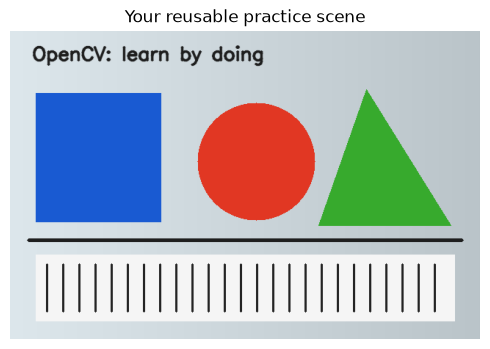

In [3]:
image = make_scene()
print("Shape:", image.shape, "Data type:", image.dtype)
print("A BGR pixel:", image[100, 100])  # row first, column second
show_images([image], ["Your reusable practice scene"])
assert image.shape == (420, 640, 3)


## Step 3 — Build a tiny pipeline

A **pipeline** applies several operations in a known order. Here we convert to
grayscale, smooth small details, and detect edges. `cvtColor` changes the color
representation. `GaussianBlur` averages nearby pixels with a center-weighted
kernel. `Canny` finds strong boundaries and keeps connected weaker boundaries.

You do not need to understand the full algorithms yet: later lessons unpack
each step. First observe how the representation changes.


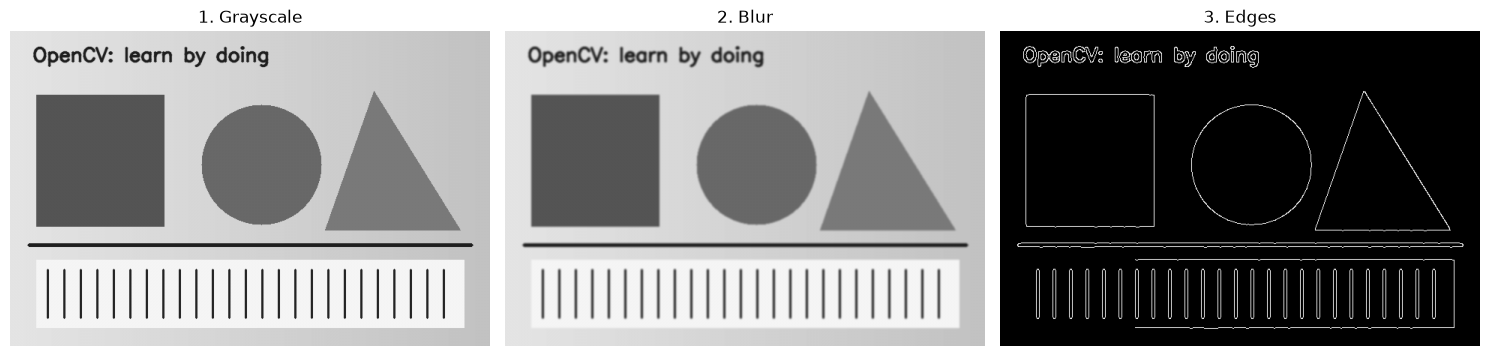

Fraction of edge pixels: 0.0332


In [4]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), sigmaX=1.2)
edges = cv2.Canny(blurred, threshold1=60, threshold2=150)
show_images([gray, blurred, edges], ["1. Grayscale", "2. Blur", "3. Edges"])
print("Fraction of edge pixels:", round(np.count_nonzero(edges) / edges.size, 4))
assert gray.shape == edges.shape == image.shape[:2]


## Step 4 — Make a prediction, change a parameter, measure

A larger blur kernel suppresses fine detail. Predict which stripes or letters will
disappear before running the next cell. Odd kernel sizes such as 3, 7, or 15 give
the kernel a center pixel. Edge count is a diagnostic, not a quality score: fewer
edges may mean less noise, or it may mean useful detail was lost.


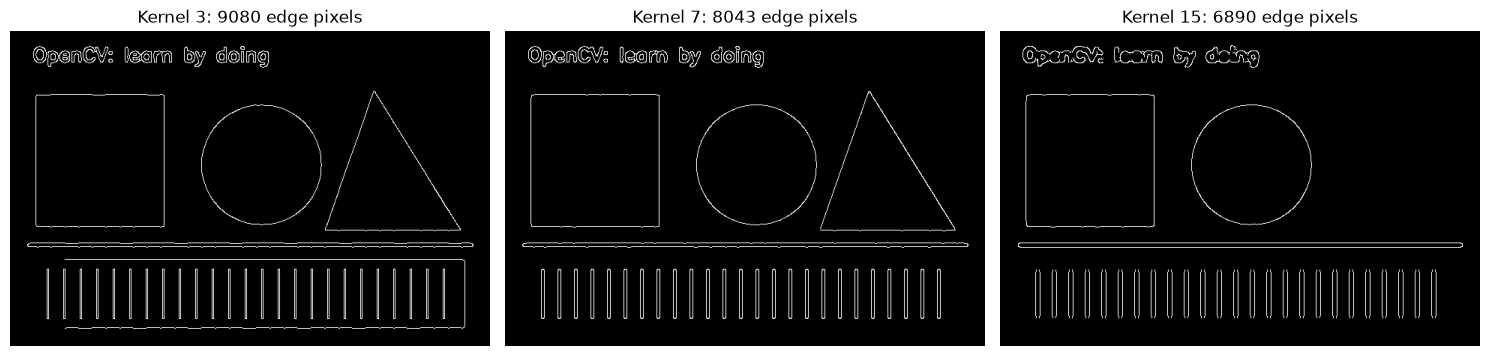

In [5]:
experiments = []
titles = []
for kernel_size in [3, 7, 15]:
    smooth = cv2.GaussianBlur(gray, (kernel_size, kernel_size), 0)
    result = cv2.Canny(smooth, 60, 150)
    experiments.append(result)
    titles.append(f"Kernel {kernel_size}: {np.count_nonzero(result)} edge pixels")
show_images(experiments, titles)


## Step 5 — Save and reload your result

Paths are anchored at `ROOT`, so you do not have to guess the notebook's current
folder. `outputs/` contains replaceable generated results. `save_image` creates
parent directories and checks encoding. `load_image` gives a clear error if a file
is missing or cannot be decoded. Notebook 02 teaches the underlying OpenCV APIs.


In [6]:
output_path = save_image(ROOT / "outputs" / "00_start" / "first_edges.png", edges)
round_trip = load_image(output_path, cv2.IMREAD_GRAYSCALE)
assert np.array_equal(round_trip, edges), "PNG should preserve these pixels exactly."
print("Saved and verified:", output_path)


Saved and verified: C:\Users\Hareram ray\AI\OpencvPractical\outputs\00_start\first_edges.png


## Mini-project — Make a contact sheet

A contact sheet puts multiple outputs beside one another. Here all images must
have the same height and channel count before concatenation. `GRAY2BGR` repeats
a gray value across three channels so the arrays have compatible shapes.


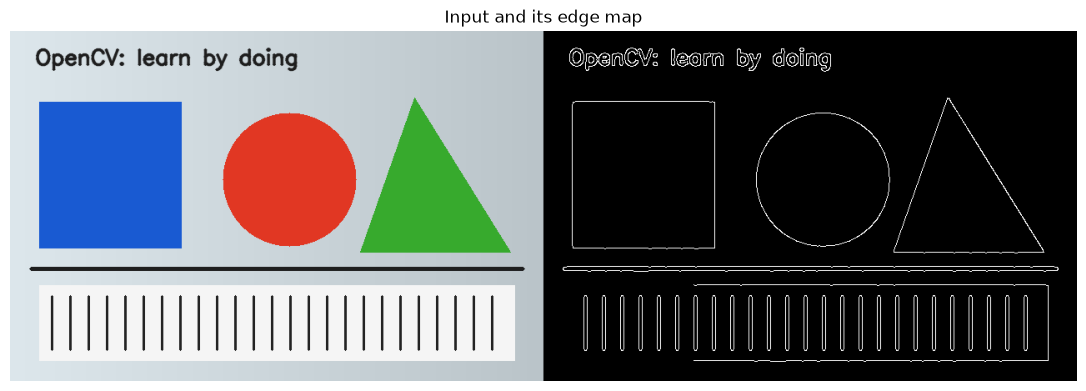

WindowsPath('C:/Users/Hareram ray/AI/OpencvPractical/outputs/00_start/contact_sheet.png')

In [7]:
edge_color = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)
contact_sheet = np.hstack([image, edge_color])
show_images([contact_sheet], ["Input and its edge map"], figsize=(12, 4))
save_image(ROOT / "outputs" / "00_start" / "contact_sheet.png", contact_sheet)


## Exercise — Try first

1. Build another edge map using thresholds 30 and 80. Does it keep more detail?
2. Crop the upper-left quarter of `image`. What should its shape be?
3. Save the crop to `outputs/00_start/my_crop.png`.

Type your code below; the empty exercise cell does not prevent Run All. Write a
sentence explaining your results before reading the solution.


In [8]:
# Your experiment goes here. Use new variable names to keep the reference intact.


## Worked solution — compare after trying


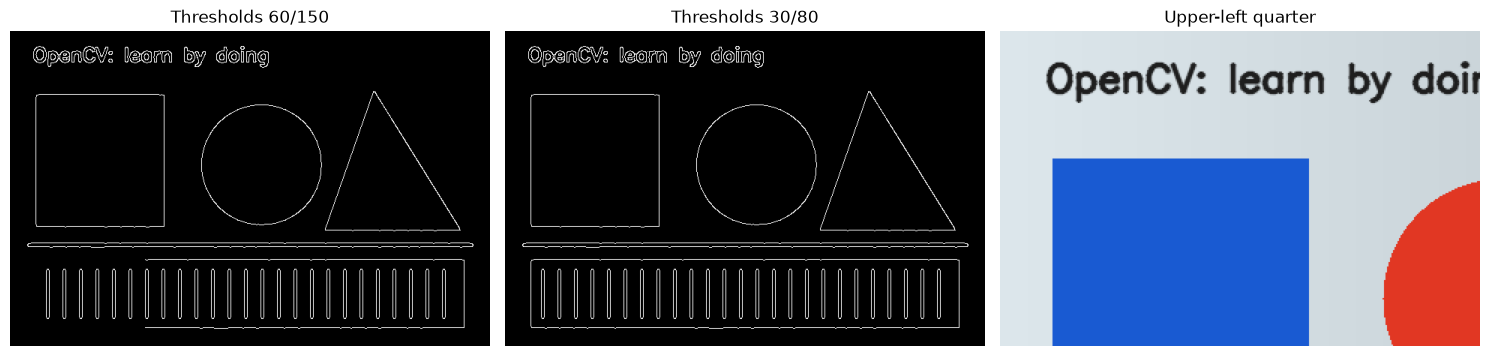

Edge counts: 8913 9296


In [9]:
extra_edges = cv2.Canny(blurred, 30, 80)
h, w = image.shape[:2]
crop = image[:h // 2, :w // 2].copy()
assert crop.shape == (210, 320, 3)
show_images([edges, extra_edges, crop], ["Thresholds 60/150", "Thresholds 30/80", "Upper-left quarter"])
save_image(ROOT / "outputs" / "00_start" / "my_crop.png", crop)
print("Edge counts:", np.count_nonzero(edges), np.count_nonzero(extra_edges))


## Use your own images

Put a photo in `data/personal/`, set `personal_path` below, and rerun this cell.
Keep the generated examples as a baseline. A method that works on clean shapes
can fail under shadows, reflections, motion blur, clutter, or new camera angles.


In [10]:
personal_path = None  # Example: ROOT / "data" / "personal" / "my_photo.jpg"
if personal_path is not None:
    personal_image = load_image(personal_path)
    show_images([personal_image], ["My own input"])
else:
    print("Optional personal image skipped. Every core lesson works without one.")


Optional personal image skipped. Every core lesson works without one.


## Your learning roadmap

| Stage | Notebooks | Milestone |
|---|---|---|
| Foundations | 01–06 | Explain image arrays and clean up a foreground mask |
| Intermediate | 07–12 | Measure objects, align images, and process video |
| Advanced | 13–17 | Track motion, reason about cameras/depth, evaluate models |
| Projects and engineering | 18–20 | Build, measure, and improve complete pipelines |

Start with [01 — NumPy and images](01_numpy_and_images.ipynb). The root README
links all 21 notebooks. No lesson relies on variables or output files from another.

Suggested eight-week plan: 00–03, 04–06, 07–09, 10–12, 13–14, 15–17, 18–19,
then 20 and an independent project. Slow down when exercises reveal gaps.

## Keep a small experiment journal

Duplicate this Markdown cell and fill it out after each lesson:

- **Question:** What am I trying to measure or detect?
- **Prediction:** What do I think will happen, and why?
- **Change:** Which single input or parameter did I change?
- **Evidence:** Which image, count, or metric supports my observation?
- **Failure:** When does the method stop working?
- **Next experiment:** What would distinguish two possible explanations?

## Readiness check

Can you explain why coordinates use row/column order, why the edge map has one
channel, and why restarting a kernel is useful? If not, notebook 01 builds those
foundations. Expertise grows from diagnosing failures on varied data, not from
memorizing OpenCV function names.

**Reference:** [Official OpenCV Python tutorials](https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html).
